# Práctica word2vec: Skip-gram


In [30]:
import re
import random
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

In [31]:
with open("dataset_word2vec.txt", encoding="utf-8") as f:
    frases = [l.strip() for l in f if l.strip()]

def tokenizar(frase):
    return re.findall(r"\w+", frase.lower())

corpus = [tokenizar(f) for f in frases]
print(len(corpus), "frases")
print(corpus[:3])

251 frases
[['el', 'perro', 'corre', 'en', 'el', 'parque'], ['el', 'perro', 'come', 'carne'], ['el', 'perro', 'bebe', 'agua']]


In [32]:
freq = Counter(w for s in corpus for w in s)
vocab = sorted(freq)
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}
V = len(vocab)

print("Tamaño del vocabulario:", V)
print(freq.most_common(10))

Tamaño del vocabulario: 356
[('la', 131), ('el', 129), ('es', 37), ('está', 27), ('en', 26), ('un', 20), ('por', 15), ('una', 15), ('al', 14), ('gato', 11)]


In [33]:
def generar_pares(corpus, window):
    pares = []
    for s in corpus:
        ids = [word2idx[w] for w in s]
        for i, centro in enumerate(ids):
            ini = max(0, i - window)
            fin = min(len(ids), i + window + 1)
            for j in range(ini, fin):
                if j != i:
                    pares.append((centro, ids[j]))
    return pares

pares_demo = generar_pares(corpus, window=2)
print(len(pares_demo), "pares")
print([(idx2word[c], idx2word[x]) for c, x in pares_demo[:8]])

3086 pares
[('el', 'perro'), ('el', 'corre'), ('perro', 'el'), ('perro', 'corre'), ('perro', 'en'), ('corre', 'el'), ('corre', 'perro'), ('corre', 'en')]


In [ ]:
class SkipGram(nn.Module):
    def __init__(self, V, D):
        super().__init__()
        self.emb = nn.Embedding(V, D)
        self.out = nn.Linear(D, V)

    def forward(self, centro):
        return self.out(self.emb(centro)) 

In [35]:
def entrenar(window=2, dim=32, epochs=100, lr=0.01, batch_size=128, seed=SEED, verbose=True):
    torch.manual_seed(seed)
    pares = torch.tensor(generar_pares(corpus, window))
    loader = DataLoader(TensorDataset(pares[:, 0], pares[:, 1]),
                        batch_size=batch_size, shuffle=True)

    model = SkipGram(V, dim)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    hist = []

    for ep in range(epochs):
        total = 0.0
        for centro, ctx in loader:
            opt.zero_grad()
            loss = loss_fn(model(centro), ctx)
            loss.backward()
            opt.step()
            total += loss.item() * len(centro)
        hist.append(total / len(pares))
        if verbose and (ep + 1) % 20 == 0:
            print(f"Época {ep+1:3d} | loss {hist[-1]:.4f}")
    return model, hist

model, hist = entrenar()

Época  20 | loss 2.8266
Época  40 | loss 2.7443
Época  60 | loss 2.7155
Época  80 | loss 2.7106
Época 100 | loss 2.7071


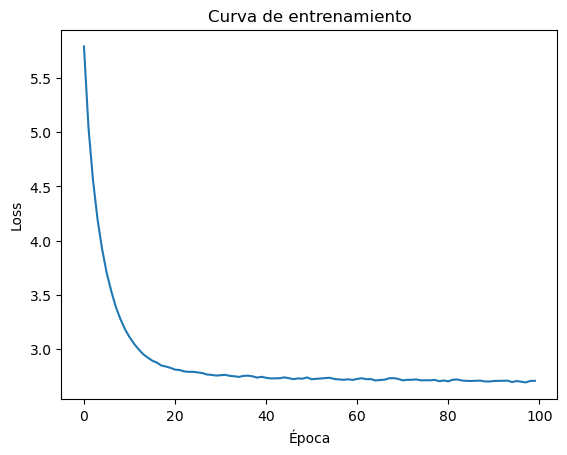

In [36]:
import matplotlib.pyplot as plt
plt.plot(hist); plt.xlabel("Época"); plt.ylabel("Loss"); plt.title("Curva de entrenamiento")
plt.show()

In [ ]:
def get_E(model):
    return F.normalize(model.emb.weight.detach(), dim=1)

def vecinos(palabra, E, k=5):
    sims = E @ E[word2idx[palabra]]
    sims[word2idx[palabra]] = -float("inf")
    top = sims.topk(k)
    return [(idx2word[i.item()], round(v.item(), 3)) for v, i in zip(top.values, top.indices)]

def analogia(a, b, c, E, k=3):
    v = F.normalize(E[word2idx[b]] - E[word2idx[a]] + E[word2idx[c]], dim=0)
    sims = E @ v
    for w in (a, b, c):
        sims[word2idx[w]] = -float("inf")
    top = sims.topk(k)
    return [(idx2word[i.item()], round(v_.item(), 3)) for v_, i in zip(top.values, top.indices)]

In [38]:
E = get_E(model)
consultas = ["perro", "gata", "coche", "parís", "francia", "madrid", "médico", "rey"]

tabla = pd.DataFrame({
    q: [f"{w} ({s})" for w, s in vecinos(q, E, k=5)] for q in consultas
}, index=[f"#{i}" for i in range(1, 6)])
tabla.T

,#1,#2,#3,#4,#5
perro,gato (0.62),coche (0.484),suelo (0.465),campo (0.463),ladra (0.43)
gata,perra (0.688),camiseta (0.53),cacao (0.505),bicicleta (0.47),entro (0.418)
coche,pintor (0.489),perro (0.484),rojo (0.44),grande (0.437),alumno (0.413)
parís,madrid (0.778),roma (0.691),montaña (0.532),españa (0.481),francia (0.454)
francia,italia (0.657),madrid (0.533),negro (0.493),españa (0.485),vive (0.485)
madrid,parís (0.778),roma (0.603),francia (0.533),vive (0.526),palacio (0.51)
médico,enfermero (0.755),médica (0.539),autobús (0.488),maúlla (0.476),baloncesto (0.474)
rey,reina (0.73),revista (0.501),fuego (0.48),corona (0.478),canta (0.436)


In [39]:
analogias = [
    ("parís", "francia", "madrid", "españa"),
    ("parís", "francia", "roma", "italia"),
    ("madrid", "españa", "roma", "italia"),
    ("perro", "perra", "gato", "gata"),
    ("médico", "médica", "maestro", "maestra"),
    ("rey", "reina", "niño", "niña"),
    ("panadero", "panadera", "cocinero", "cocinera"),
]

filas = []
for a, b, c, esperado in analogias:
    top = analogia(a, b, c, E, k=3)
    filas.append({
        "analogía": f"{a} : {b} :: {c} : ?",
        "esperado": esperado,
        "top-3": ", ".join(f"{w} ({s})" for w, s in top),
        "acierto": top[0][0] == esperado,
    })
pd.DataFrame(filas)

,analogía,esperado,top-3,acierto
0,parís : francia :: madrid : ?,españa,"italia (0.563), vive (0.496), cerrada (0.478)",False
1,parís : francia :: roma : ?,italia,"italia (0.619), corto (0.501), gato (0.396)",True
2,madrid : españa :: roma : ?,italia,"gris (0.533), italia (0.5), libro (0.48)",False
3,perro : perra :: gato : ?,gata,"gata (0.735), bicicleta (0.545), tiene (0.539)",True
4,médico : médica :: maestro : ?,maestra,"voy (0.525), sal (0.494), historia (0.474)",False
5,rey : reina :: niño : ?,niña,"niña (0.695), canción (0.525), fuente (0.48)",True
6,panadero : panadera :: cocinero : ?,cocinera,"prepara (0.479), de (0.471), amarilla (0.462)",False


In [40]:
palabras_analogias = sorted({w for t in analogias for w in t})
pd.DataFrame({
    "palabra": palabras_analogias,
    "frecuencia": [freq[w] for w in palabras_analogias],
}).sort_values("frecuencia").reset_index(drop=True)

,palabra,frecuencia
0,cocinera,1
1,cocinero,1
2,panadero,1
3,panadera,1
4,maestra,1
5,reina,2
6,parís,2
7,médico,2
8,rey,2
9,médica,2


In [41]:
top1 = sum(analogia(a, b, c, E, k=1)[0][0] == esp for a, b, c, esp in analogias)
top3 = sum(esp in [w for w, _ in analogia(a, b, c, E, k=3)] for a, b, c, esp in analogias)
print(f"Top-1: {top1}/{len(analogias)} | Top-3: {top3}/{len(analogias)}")

Top-1: 3/7 | Top-3: 4/7


In [ ]:
configs = [
    {"window": 1, "dim": 32, "epochs": 100, "lr": 0.01},
    {"window": 2, "dim": 32, "epochs": 100, "lr": 0.01},
    {"window": 4, "dim": 32, "epochs": 100, "lr": 0.01},  
    {"window": 2, "dim": 8,  "epochs": 100, "lr": 0.01},  
    {"window": 2, "dim": 100,"epochs": 100, "lr": 0.01},  
    {"window": 2, "dim": 32, "epochs": 10,  "lr": 0.01}, 
    {"window": 2, "dim": 32, "epochs": 100, "lr": 0.001},
]

resultados = []
for cfg in configs:
    m, h = entrenar(**cfg, verbose=False)
    Ec = get_E(m)
    aciertos = sum(analogia(a, b, c, Ec, k=1)[0][0] == esp for a, b, c, esp in analogias)
    resultados.append({
        **cfg,
        "loss final": round(h[-1], 3),
        "analogías ok": f"{aciertos}/{len(analogias)}",
        "vecinos de 'perro'": ", ".join(w for w, _ in vecinos("perro", Ec, 4)),
    })
pd.DataFrame(resultados)

,window,dim,epochs,lr,loss final,analogías ok,vecinos de 'perro'
0,1,32,100,0.010,2.246,2/7,"coche, gato, campo, cerrado"
1,2,32,100,0.010,2.707,3/7,"gato, coche, suelo, campo"
2,4,32,100,0.010,3.005,4/7,"gato, perra, grande, ladra"
3,2,8,100,0.010,2.960,5/7,"gato, come, ratón, duerme"
4,2,100,100,0.010,2.849,0/7,"gato, patio, panadero, lento"
5,2,32,10,0.010,3.184,1/7,"suelo, coche, como, campo"
6,2,32,100,0.001,3.010,1/7,"coche, suelo, como, campo"


In [43]:
seeds = [0, 1, 2, 3, 4]
filas = []
for cfg in configs:
    acc, losses = [], []
    for s in seeds:
        m, h = entrenar(**cfg, seed=s, verbose=False)
        Ec = get_E(m)
        acc.append(sum(analogia(a, b, c, Ec, k=1)[0][0] == esp for a, b, c, esp in analogias))
        losses.append(h[-1])
    filas.append({**cfg,
                  "loss final": round(np.mean(losses), 3),
                  "analogías ok (media ± std)": f"{np.mean(acc):.1f} ± {np.std(acc):.1f} / {len(analogias)}"})
pd.DataFrame(filas)

,window,dim,epochs,lr,loss final,analogías ok (media ± std)
0,1,32,100,0.010,2.257,0.8 ± 1.2 / 7
1,2,32,100,0.010,2.703,2.0 ± 0.9 / 7
2,4,32,100,0.010,3.004,2.8 ± 1.0 / 7
3,2,8,100,0.010,2.932,4.4 ± 0.8 / 7
4,2,100,100,0.010,2.822,0.8 ± 0.7 / 7
5,2,32,10,0.010,3.175,0.2 ± 0.4 / 7
6,2,32,100,0.001,3.002,0.2 ± 0.4 / 7


In [44]:
for cfg in [{"window": 4, "dim": 8}, {"window": 2, "dim": 8}, {"window": 4, "dim": 16}]:
    acc = []
    for s in range(5):
        m, _ = entrenar(**cfg, epochs=100, lr=0.01, seed=s, verbose=False)
        Ec = get_E(m)
        acc.append(sum(analogia(a, b, c, Ec, k=1)[0][0] == esp for a, b, c, esp in analogias))
    print(cfg, f"{np.mean(acc):.1f} ± {np.std(acc):.1f} / {len(analogias)}")

{'window': 4, 'dim': 8} 3.8 ± 1.2 / 7
{'window': 2, 'dim': 8} 4.4 ± 0.8 / 7
{'window': 4, 'dim': 16} 4.2 ± 0.4 / 7


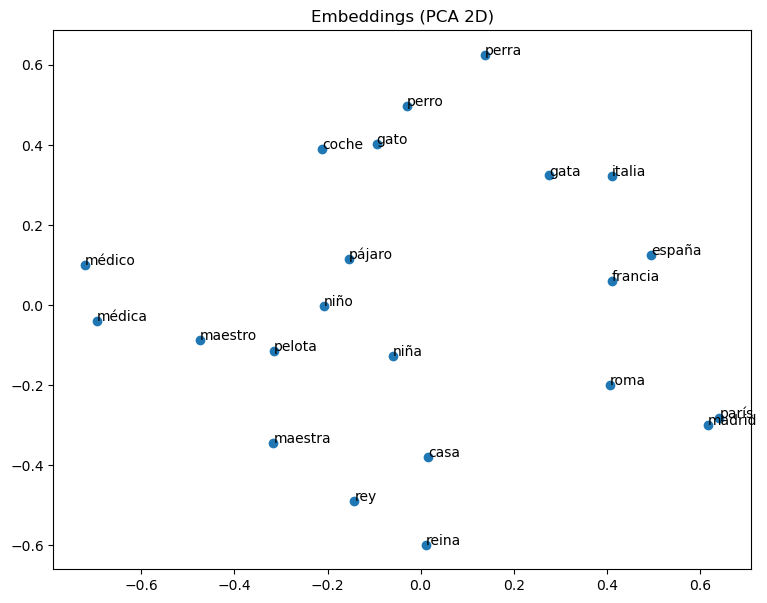

In [45]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

palabras = ["perro","perra","gato","gata","pájaro","parís","madrid","roma","francia","españa","italia",
            "médico","médica","maestro","maestra","rey","reina","niño","niña","coche","casa","pelota"]
X = PCA(n_components=2).fit_transform(E[[word2idx[w] for w in palabras]].numpy())

plt.figure(figsize=(9, 7))
plt.scatter(X[:, 0], X[:, 1])
for (x, y), w in zip(X, palabras):
    plt.annotate(w, (x, y))
plt.title("Embeddings (PCA 2D)")
plt.show()